## Balcony solar panels

Up until recently, the only option to have local production of electricity through solar panels would have been through the installation of rooftop solar panels. The rooftop is generally the most efficient place to install solar panels because it generally has a large area and direct view of the sky. However, rooftop solar also requires electrical works to connect the solar panels and inverters to the home's electrical system.

Recently, a new type of solar system has been introduced on the market, which does not require any type of electrical work because it connects directly to the standard electrical plugs. For this reason, it is called "plug and play" solar. This lower technical requirement in theory provides much easier access to solar generation also to renters, who could install the solar panels on their balcony, for example. However, plug and play solar also comes with a series of constraints. A smart meter is required, the power of the inverter is limited to only 800 W,[^1] and urbanistic requirements also have to be taken into consideration. Finally, plug and play solar is not eligible for green certificates.

[^1]: Synergrid has published a technical directive listing the requirements for plug and play devices that can store or generate electrical energy. They also provide a list indicating which equipment is homologated to be used in Belgium.

The question is then, does it make sense to buy them? This depends of course on the amount of energy that can be harvested from the sun, and the electric energy that is consumed by the dwelling. Below, I will provide the calculation for my apartment, in the hope that it can be a useful rule of thumb. The code is also provided, so it can be adapted to different situations.

## Calculating the solar radiation

The amount of solar energy that hits a solar panel installed on a balcony depends on a variety of factors:
* The orientation of the solar panel (azimuth). Ideally, it should be towards the South (180 degrees), but anything from East (90 degrees) to West (270) can be considered. Outside of this range, there is not enough sunlight to justify the installation of a solar panel.
* The slope of the solar panel, i.e. the tilt from the surface parallel to the ground. For a panel that is attached to the exterior facade of the balcony, the slope is usually fixed at 90 degrees which is not ideal especially for the summer months where the sun is high in the sky.
* Surrounding buildings. In a city such as Brussels, buildings can block the Sun for long hours each days, substantially reducing the amount of direct light hitting the solar panel.
* The cloud cover, which is, of course, quite a big problem in Brussels.

Historic irradiance data (i.e., the amount of solar energy hitting a specific surface) based on the azimuth and the slope can be easily retrieved using a tool such as [PVGIS](https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system-pvgis_en): you need to provide the address of your home, then you have to fill the information related to the orientation, slope and horizon (i.e., the occlusion caused by the surrounding buildings). The balcony in my apartment is located in direction SW (azimuth = 223 degrees) and the slope of a potential PV panel attached to the balcony would be 90 degrees. 

Unfortunately, the information regarding the horizon is much harder to get. The way I managed to do it is by exploiting the UrbIS Buildings dataset. This dataset contains the 3D data for all the buildings in the Brussels Region. The data can be downloaded and analyzed using the geopandas Python library. Doing this, I managed to reconstruct the horizon elevation that I see from my balcony for each azimuthal degree.

In my calculations, I used the [pvlib](https://pvlib-python.readthedocs.io/en/stable/) Python library, which is a community based tool evolved from an original package developed by the SANDIA national laboratories.  


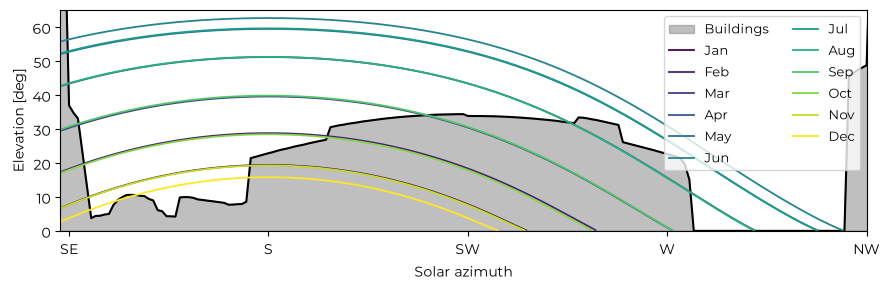

In [26]:
from pathlib import Path
import pvlib
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

for f in Path("fonts").glob("*.ttf"):   # path relative to the notebook
    fm.fontManager.addfont(str(f))

plt.rcParams["font.family"] = "Montserrat"

# read the horizon data
hz = pd.read_csv("../data/horizon_balcony.csv")

# location in Brussels
latitude = 50.817205
longitude = 4.377434
azimuth = 223  # SW

# Belgian time zone
tz = "Europe/Brussels"
year = 2026

dates = pd.to_datetime([
    f"{year}-01-21",
    f"{year}-02-21",
    f"{year}-03-21",
    f"{year}-04-21",
    f"{year}-05-21",
    f"{year}-06-21",
    f"{year}-07-21",
    f"{year}-08-21",
    f"{year}-09-21",
    f"{year}-10-21",
    f"{year}-11-21",
    f"{year}-12-21",
])

solar_paths = {}

for date in dates:
    times = pd.date_range(start=date, end=date + pd.Timedelta(days=1), freq="2min", tz=tz)
    solar_position = pvlib.solarposition.get_solarposition(times, latitude, longitude)

    # keep Sun above astronomical horizon
    solar_position = solar_position[solar_position["apparent_elevation"] > 0]
    solar_paths[date.strftime("%b")] = solar_position


fig, ax = plt.subplots(figsize=(9, 3))
az_horizon = hz["azimuth"].values
el_horizon = hz["horizon_height"].values

ax.fill_between(az_horizon, 0, el_horizon, color="gray", alpha=0.5, label="Buildings")
ax.plot(az_horizon, el_horizon, color="black", linewidth=1.5)

cmap = plt.cm.viridis
for i, (month, sun) in enumerate(solar_paths.items()):
    # keep Sun within the visible range
    mask = ((sun["azimuth"] >= 0) &(sun["azimuth"] <= 360))
    ax.plot(sun.loc[mask, "azimuth"], sun.loc[mask, "apparent_elevation"], color=cmap(i / 11), linewidth=1.3, label=month)

ax.set_xlim(azimuth-90, azimuth+90)
ax.set_ylim(0, 65)

ax.set_xticks([135, 180, 225, 270, 315], ["SE", "S", "SW", "W", "NW"])
ax.set_xlabel("Solar azimuth")
ax.set_ylabel("Elevation [deg]")
ax.legend(ncol=2, loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()


As you can see, I have quite a big building in front of my balcony. During the summer months, the sun is higher than the building for most of the day. However, this means also that it will hit the solar panel with a large angle, which is not ideal. During the winter months, the solar panel will get a bit of sunlight only during late morning. 

Through pvlib, I have also retrieved the solar irradiance data for the last 5 years available, from 2018 to 2023. This data has hourly information on the irradiance, divided into the direct energy (the solar rays that hit the panel directly and that can be blocked by the buildings) and diffuse energy, which is the light scattered by the sky and coming from all directions. 

For example, on the 11th of October 2023, the Sun would have hit directly my solar panel only between 11:00 and 15:00, while the diffuse radiation would have contributed from 9:00 to 18:00. POA stands for plane of array, meaning that we are taking into account the tilt of the surface when computing the irradiance.

In [27]:
# PVGIS data for 5 years
import numpy as np
import pandas as pd
import pvlib
from pvlib.iotools import get_pvgis_hourly
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

lat, lon, alt = 50.817205, 4.377434, 90.452
tilt, azimuth = 90, 223          # vertical, south-facing (pvlib: 180 = south)
tz = "Europe/Brussels"

data, meta = get_pvgis_hourly(
    latitude=lat,
    longitude=lon,
    start=2019,
    end=2023,
    raddatabase="PVGIS-SARAH3",
    components=True,
    surface_tilt=tilt,
    surface_azimuth=azimuth,
    usehorizon=False
)

data.index = data.index.tz_convert("Europe/Brussels")
site = pvlib.location.Location(latitude=lat, longitude=lon, tz=tz, altitude=alt)
solpos = site.get_solarposition(data.index)

hz = pd.read_csv("../data/horizon_balcony.csv")
hz_az, hz_hg = hz["azimuth"].values, hz["horizon_height"].values
sun_horizon = np.interp(solpos["azimuth"], hz_az, hz_hg, period=360)
blocked = (solpos["apparent_elevation"] <= sun_horizon)
data["poa_direct_corr"] = data["poa_direct"].where(~blocked, 0.0)

h = np.radians(hz_hg)
diff = ((hz_az - azimuth + 180) % 360) - 180
front = np.abs(diff) <= 90
weights = np.cos(np.radians(diff[front]))

svf = np.sum(weights * np.cos(h[front])**2) / np.sum(weights)

data['poa_diffuse'] = svf*data['poa_sky_diffuse'] + data['poa_ground_diffuse']
data['poa_global'] = data['poa_direct_corr'] + data['poa_diffuse']

data = data.iloc[:-1]  # drop last row 

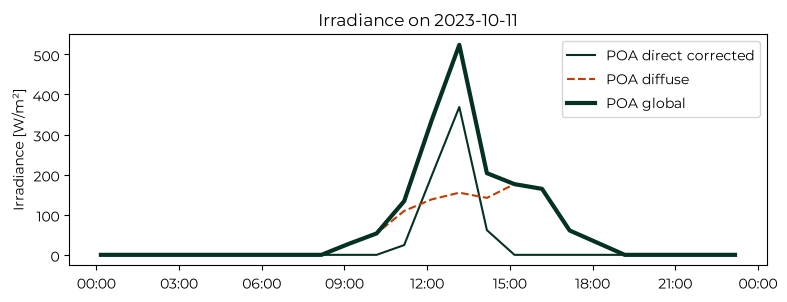

In [28]:
day = "2023-10-11"
day_end = "2023-10-11 23:59"

fig, ax = plt.subplots(figsize=(9,3))
ax.plot(data["poa_direct_corr"].loc[day], label="POA direct corrected", c='#043122')
ax.plot(data["poa_diffuse"].loc[day], label="POA diffuse", c='#C03C04', ls='--')
ax.plot(data["poa_global"].loc[day], label="POA global", c ='#043122', lw=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=tz))
ax.set_ylabel("Irradiance [W/m²]")
ax.set_title(f"Irradiance on {day}")
ax.legend()
ax.grid(False)

plt.show()

Once we know the solar irradiance, we can compute how much energy the solar panel would gather each year. To perform the calculation I’m employing the following setup:
* Number of solar panels: 2
* Length of the solar panel: 1.96 m
* Height of the solar panel: 1.134 m
* Total area: 4.45 m2
* Efficiency of the solar panel: 25.3%
* Total efficiency of the system: 85%
* Nominal power: 1000 W
* Inverter: 800 W (this should be the maximum allowed for plug & play installations)
* Price: 550 Eur

The yearly amount of energy that would have been produced by the PV system fluctuates around 500/600 kWh. 

In [29]:
# Power output
from pvlib.temperature import sapm_cell
temp_cell = sapm_cell(
    poa_global=data["poa_global"],
    temp_air=data["temp_air"],
    wind_speed=data["wind_speed"],
    a=-3.56,
    b=-0.075,
    deltaT=3
)

n_panels = 2
length = 1.96  #m
height = 1.134  #m
area = n_panels * length * height #m2
eta_panel = 0.253
eta_sys = 0.85
P_nom = n_panels * 500 #W
price = 550  #Eur

gamma = -0.0035  # 1/°C
power = (data["poa_global"]* P_nom/1000 * (1 + gamma*(temp_cell - 25)))

data['P_prod'] = power * eta_sys  #W
data['E_prod'] = data['P_prod']/1000  # kWh


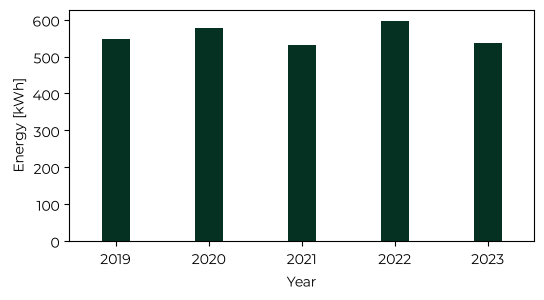

Average yearly production 2018-2023: 557.88 kWh


In [30]:
# Plot yearly production
yearly = data['E_prod'].resample("YE").sum()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(yearly.index.year, yearly.values, width=0.3, color='#043122')
ax.set_xlabel("Year")
ax.set_xlim(2018.5, 2023.5)
ax.set_ylabel("Energy [kWh]")
plt.show()

print(f"Average yearly production 2018-2023: {yearly.mean():.2f} kWh")

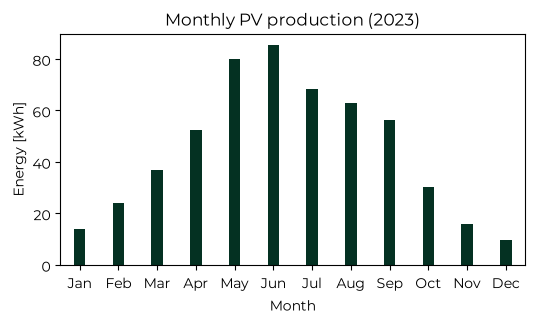

In [31]:
# Plot monthly production
monthly_2023 = (data.loc["2023", "E_prod"].resample("ME").sum())
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(monthly_2023.index.month, monthly_2023.values, width=0.3, color='#043122')
ax.set_xlabel("Month")
ax.set_xlim(0.5, 12.5)
ax.set_ylabel("Energy [kWh]")
ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Monthly PV production (2023)")
plt.show()

I can also plot the monthly production for the year 2023. Given my orientation, the best months would be from April to September, with a sharp drop from October to March.

## Consumption

Unfortunately, I don't have a smart meter yet so I don't know precisely what is the hourly distribution of my energy consumption yet. To have a first order approximation, first I will assume that my apartment consumes the same as the average yearly consumption in Ixelles, which is 2000 kWh/year. In the next [chapter](./02_energy-consumption.ipynb), I will have a more in depth look at the energy consumption in the Brussels region.

Given that we have computed an annual PV generation in the order of 600 kWh, this represents almost a third of the energy consumed, which is not an insignificant contribution. However, this does not automatically mean that my annual energy bill would be lower by a third. In fact, to understand how much I would save from installing solar panels I need to consider the temporal distribution of my consumption. If, for example, I’m running my dishwasher while the sun is out, then I will actually use solar energy to wash my dishes instead of using the grid’s current.  But of course it’s impossible to concentrate all the energy consumption when the sun is shining. If the generation of electrical energy is greater than the consumption, then the surplus is injected and sold to the grid.

This mismatch between consumption and generation would not be a big deal from an economical point of view if the cost of electricity bought from the grid was the same as the price of electricity sold to the grid. Unfortunately, these two are quite different: we can consider that the cost of electricity in Brussels is around 0.2-0.3 Eur/kWh while the price paid to the electricity produced by the PV panels and injected into the grid is around 0.05-0.1 Eur/kWh. 

This is the reason why electric storage, in the form of batteries, is very often paired with PV panels. The idea is to store the excess energy produced during the day and use it during the evening, which is generally when most of the consumption takes place. 

To understand what would be the economical benefit of PV panels setup, with and without batteries, it is then necessary to know the temporal distribution of my electrical consumption. The second assumption is to assume that my consumption is distributed similarly to the real load profile published by Synergrid: given a total yearly consumption, it calculates how this consumption is distributed over the year in 15 min intervals. 

Given my yearly consumption of 2000 kWh, the distribution of consumption and production looks like this:

In [32]:
rlp = pd.read_excel("../data/RLP0N 2026 Electricity.xlsb", sheet_name="RLP96U", skiprows=5, engine="calamine")
rlp = rlp.set_index("CET")

# Scale to average Ixelles annual consumption
E_cons_median = 2000  # kWh/year
rlp["E_cons"] = (E_cons_median * rlp["RLPestU"])

# Convert quarter-hourly to hourly
rlp_hourly = (rlp["E_cons"].resample("h").sum())

rlp_lookup = pd.DataFrame({
    "month": rlp_hourly.index.month,
    "day": rlp_hourly.index.day,
    "hour": rlp_hourly.index.hour,
    "E_cons": rlp_hourly.values
})

data["month"] = data.index.month
data["day"] = data.index.day
data["hour"] = data.index.hour

data_load = data.copy()
data_load["timestamp"] = data.index

data_load = data_load.merge(rlp_lookup, on=["month", "day", "hour"], how="left")
data_load = data_load.set_index("timestamp")
data_load["E_cons"] = data_load["E_cons"].fillna(data_load["E_cons"].shift(24))

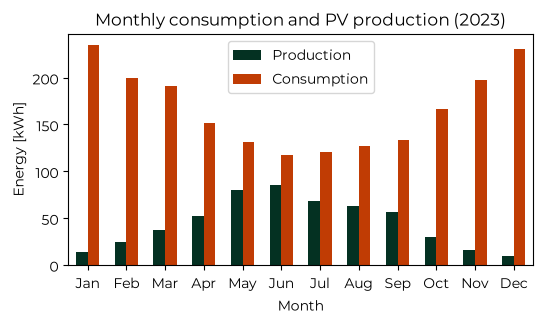

In [33]:
fig, ax = plt.subplots(figsize=(6, 3))

x = np.arange(1, 13)
width = 0.3

monthly_prod = (data_load.loc["2023", "E_prod"].resample("ME").sum())
ax.bar(x-width/2, monthly_prod.values, width=width, color='#043122', label="Production")

monthly_load = (data_load.loc["2023", "E_cons"].resample("ME").sum())
ax.bar(x+width/2, monthly_load.values, width=width, color='#C03C04', label="Consumption")

ax.set_xlabel("Month")
ax.set_xlim(0.5, 12.5)
ax.set_ylabel("Energy [kWh]")
ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Monthly consumption and PV production (2023)")
ax.legend()
plt.show()

The pattern of consumption is basically the opposite of production, with higher consumption in the winter months. This is probably a combination of the increased lighting and heating needed in winter.
With this information, we can check for every hour what is the ratio between the energy consumed and energy produced. If the energy produced is lower than the energy consumed, we are saving on the consumption (i.e. saving 0.3 Eur for each kWh produced). If the energy produced is greater than the energy consumed, we are saving the energy consumed at 0.3 Eur/kWh and we are selling the excess at 0.05 Eur/kWh.


In [34]:
data_load["E_grid"] = data_load["E_prod"] - data_load["E_cons"]
data_load["self_consumed"] = data_load["E_prod"] - np.maximum(data_load["E_grid"], 0)

buy_price = 0.3  # €/kWh
sell_price = 0.05  # €/kWh

data_load["money_saved"] = data_load["self_consumed"] * buy_price
data_load["money_earned"] = np.maximum(data_load["E_grid"], 0) * sell_price  

money_saved = data_load["money_saved"].sum()
money_earned = data_load["money_earned"].sum()
money_total = money_saved + money_earned

yearly_total = money_total / 5  # average over 5 years
money_total_30y = yearly_total * 30  # over 30 years

print(f'Money saved 2018-2023: {data_load["money_saved"].sum():.2f} €')
print(f'Money earned 2018-2023: {data_load["money_earned"].sum():.2f} €')
print(f'Total 2018-2023: {data_load["money_saved"].sum() + data_load["money_earned"].sum():.2f} €')

print(f'Average yearly total: {yearly_total:.2f} €')
print(f'Total over 30 years: {money_total_30y:.2f} €')

Money saved 2018-2023: 563.98 €
Money earned 2018-2023: 45.47 €
Total 2018-2023: 609.45 €
Average yearly total: 121.89 €
Total over 30 years: 3656.73 €


Given this setup, the resulting profit for 5 years would be:
* Money saved: 564.95 Eur,
* Money earned: 45.31 Eur,
* Total: 610.26 Eur,

meaning that I would break even with the investment at around 5 years after installation. Given that the solar panels are generally rated for around 25/30 years of operation, this can be interesting from an economic point of view. In particular, at a yearly rate of 122.05 Eur the investment for 30 years would yield 3661.57 euros.

Of course this depends on the cost of electricity, and the investment would make less sense if you are able to secure a cheaper contract. 